# Bài 1: Phân tích 3 đặc trưng trong bộ dữ liệu Diabetes
Trong bài tập này, chúng ta sẽ tải bộ dữ liệu Diabetes, chọn ra 3 đặc trưng quan trọng (`bmi`, `s5`, `bp`), sau đó tiến hành phân tích phân phối, kiểm tra outlier bằng IQR, tính hệ số tương quan với `target` và vẽ biểu đồ scatter plot.

In [1]:
# Import các thư viện cần thiết
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Cấu hình hiển thị đồ họa trên Jupyter Notebook
%matplotlib inline
sns.set_theme(style="whitegrid")

# Tải bộ dữ liệu Diabetes từ sklearn
from sklearn.datasets import load_diabetes

diabetes = load_diabetes(as_frame=True)
df = diabetes.data.copy()
df['target'] = diabetes.target

print("Kích thước bộ dữ liệu:", df.shape)
df.head()


Kích thước bộ dữ liệu: (442, 11)


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


## 1. Thống kê và kiểm tra Outliers cho 3 đặc trưng (`bmi`, `s5`, `bp`)

In [2]:
features = ['bmi', 's5', 'bp']
stats_list = []

for col in features:
    mean_val = df[col].mean()
    std_val = df[col].std()
    min_val = df[col].min()
    max_val = df[col].max()
    
    # Tính IQR và số lượng outlier
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    
    n_outliers = ((df[col] < lower_bound) | (df[col] > upper_bound)).sum()
    corr = df[col].corr(df['target'])
    
    stats_list.append({
        'Feature': col,
        'Mean': round(mean_val, 4),
        'Std': round(std_val, 4),
        'Min': round(min_val, 4),
        'Max': round(max_val, 4),
        'Outliers (IQR)': n_outliers,
        'Correlation with Target': round(corr, 4)
    })

stats_df = pd.DataFrame(stats_list)
stats_df

,Feature,Mean,Std,Min,Max,Outliers (IQR),Correlation with Target
0,bmi,-0.0,0.0476,-0.0903,0.1706,3,0.5865
1,s5,0.0,0.0476,-0.1261,0.1336,4,0.5659
2,bp,-0.0,0.0476,-0.1124,0.1320,0,0.4415


## 2. Vẽ biểu đồ Phân phối (Distribution) và Biểu đồ hộp (Boxplot) kiểm tra Outliers

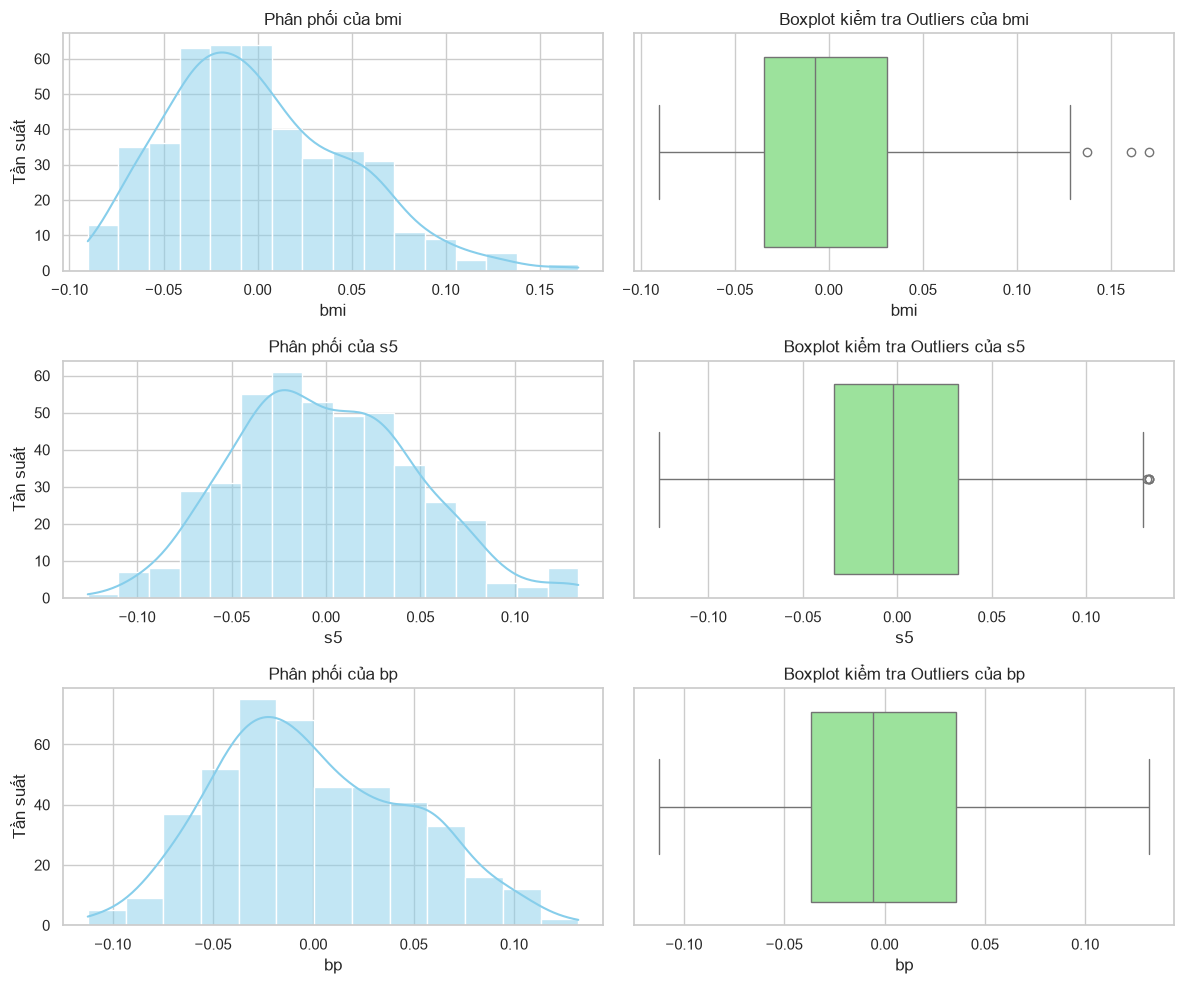

In [3]:
fig, axes = plt.subplots(len(features), 2, figsize=(12, 10))
for i, col in enumerate(features):
    # Histogram + KDE (Phân phối)
    sns.histplot(df[col], kde=True, ax=axes[i, 0], color='skyblue')
    axes[i, 0].set_title(f'Phân phối của {col}')
    axes[i, 0].set_xlabel(col)
    axes[i, 0].set_ylabel('Tần suất')
    
    # Boxplot (Outliers)
    sns.boxplot(x=df[col], ax=axes[i, 1], color='lightgreen')
    axes[i, 1].set_title(f'Boxplot kiểm tra Outliers của {col}')
    axes[i, 1].set_xlabel(col)

plt.tight_layout()
plt.show()

## 3. Vẽ Scatter Plot giữa các Feature (`bmi`, `s5`, `bp`) và Biến mục tiêu (`target`)

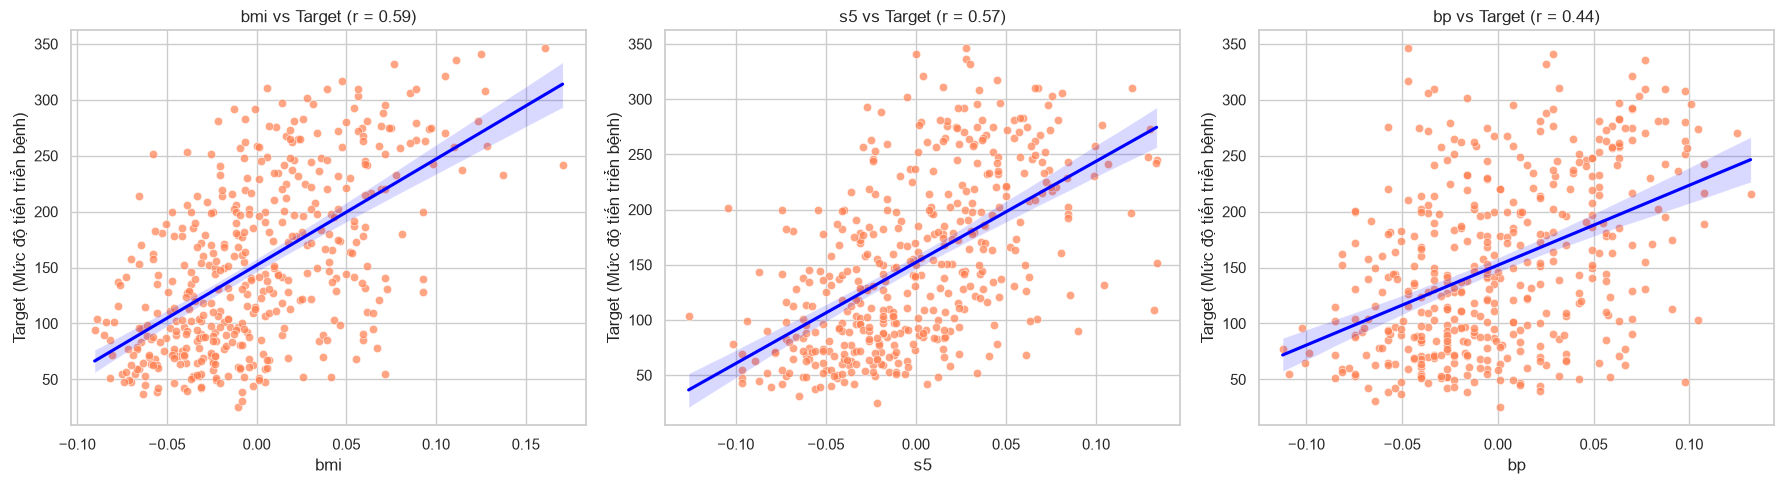

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for i, col in enumerate(features):
    sns.scatterplot(x=df[col], y=df['target'], ax=axes[i], alpha=0.7, color='coral')
    sns.regplot(x=df[col], y=df['target'], ax=axes[i], scatter=False, color='blue')
    corr = df[col].corr(df['target'])
    axes[i].set_title(f'{col} vs Target (r = {corr:.2f})')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Target (Mức độ tiến triển bệnh)')

plt.tight_layout()
plt.show()